# Formative 2: Tabular Data Preprocessing

This notebook explores and combines the supplied customer transaction and social-profile datasets to prepare a transaction-level dataset for predicting `product_category`.

**Important:** social IDs appear to use an `A` prefix (such as `A151`) while transaction IDs are numeric (such as `151`). Removing the prefix is treated as a *candidate mapping*, not a confirmed fact. Verify it against the dataset documentation or facilitator before relying on it.

## 1. Imports and input files

Put the two CSV files in `data/raw/` or in the repository root. The loader checks both locations.

In [4]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

def find_file(names):
    candidates = [ROOT / "data" / "raw" / n for n in names] + [ROOT / n for n in names]
    for path in candidates:
        if path.exists():
            return path
    raise FileNotFoundError("Could not find: " + ", ".join(names))

tx_path = find_file(["customer_transactions.csv",
                     "customer_transactions - customer_transactions.csv"])
social_path = find_file(["customer_social_profiles.csv",
                         "customer_social_profiles - customer_social_profiles.csv"])

transactions = pd.read_csv(tx_path)
social = pd.read_csv(social_path)
print("Transactions:", transactions.shape, tx_path)
print("Social profiles:", social.shape, social_path)
display(transactions.head())
display(social.head())

Transactions: (150, 6) c:\Users\a\Documents\formative_2_data_processing_personal\data\raw\customer_transactions.csv
Social profiles: (155, 5) c:\Users\a\Documents\formative_2_data_processing_personal\data\raw\customer_social_profiles.csv


,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating
0,151,1001,408,2024-01-01,Sports,2.3
1,192,1002,332,2024-01-02,Electronics,4.2
2,114,1003,442,2024-01-03,Electronics,2.1
3,171,1004,256,2024-01-04,Clothing,2.8
4,160,1005,64,2024-01-05,Clothing,1.3


,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment
0,A178,LinkedIn,74,4.9,Positive
1,A190,Twitter,82,4.8,Neutral
2,A150,Facebook,96,1.6,Positive
3,A162,Twitter,89,2.6,Positive
4,A197,Twitter,92,2.3,Neutral


## 2. Initial data audit

Before merging, inspect each table's size, column types, missing values, duplicate rows, and the target distribution.

--- Transactions ---
Shape: (150, 6)


,dtype
customer_id_legacy,int64
transaction_id,int64
purchase_amount,int64
purchase_date,str
product_category,str
customer_rating,float64


,missing values
customer_id_legacy,0
transaction_id,0
purchase_amount,0
purchase_date,0
product_category,0
customer_rating,10


Exact duplicate rows: 0


,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating
0,151,1001,408,2024-01-01,Sports,2.3
1,192,1002,332,2024-01-02,Electronics,4.2
2,114,1003,442,2024-01-03,Electronics,2.1
3,171,1004,256,2024-01-04,Clothing,2.8
4,160,1005,64,2024-01-05,Clothing,1.3


--- Social profiles ---
Shape: (155, 5)


... (2 outputs left out)

Exact duplicate rows: 5


,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment
0,A178,LinkedIn,74,4.9,Positive
1,A190,Twitter,82,4.8,Neutral
2,A150,Facebook,96,1.6,Positive
3,A162,Twitter,89,2.6,Positive
4,A197,Twitter,92,2.3,Neutral


Product category distribution:


,count
product_category,
Sports,35
Electronics,34
Clothing,28
Groceries,28
Books,25


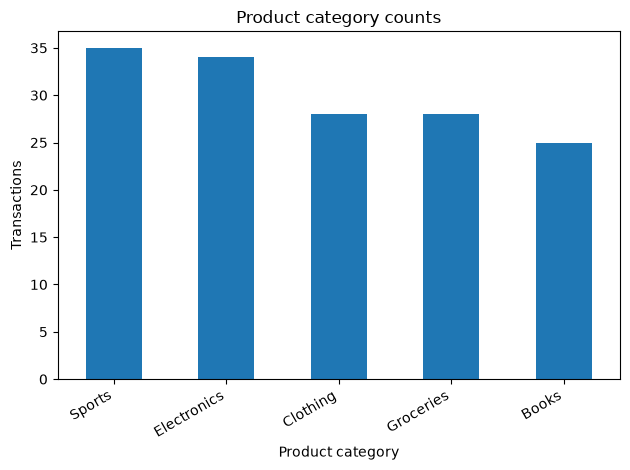

In [5]:
def audit(df, name):
    print(f"--- {name} ---")
    print("Shape:", df.shape)
    display(df.dtypes.rename("dtype").to_frame())
    display(df.isna().sum().rename("missing values").to_frame())
    print("Exact duplicate rows:", df.duplicated().sum())
    display(df.head())

audit(transactions, "Transactions")
audit(social, "Social profiles")

print("Product category distribution:")
display(transactions["product_category"].value_counts(dropna=False).to_frame("count"))
transactions["product_category"].value_counts().plot(kind="bar", title="Product category counts")
plt.xlabel("Product category")
plt.ylabel("Transactions")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 3. Validate columns and clean data types

The transaction table is the primary table because each row represents a transaction. Rows without a customer ID or target label cannot be used in the supervised modelling dataset.

In [6]:
required_tx = {"customer_id_legacy", "transaction_id", "purchase_amount",
               "purchase_date", "product_category", "customer_rating"}
required_social = {"customer_id_new", "social_media_platform", "engagement_score",
                   "purchase_interest_score", "review_sentiment"}

assert required_tx.issubset(transactions.columns), f"Missing transaction columns: {required_tx - set(transactions.columns)}"
assert required_social.issubset(social.columns), f"Missing social columns: {required_social - set(social.columns)}"

tx = transactions.copy()
sp = social.copy()

tx["customer_id_legacy"] = tx["customer_id_legacy"].astype("string").str.strip()
sp["customer_id_new"] = sp["customer_id_new"].astype("string").str.strip()
tx["purchase_date"] = pd.to_datetime(tx["purchase_date"], errors="coerce")
tx["product_category"] = tx["product_category"].astype("string").str.strip()

for col in ["purchase_amount", "customer_rating"]:
    tx[col] = pd.to_numeric(tx[col], errors="coerce")
for col in ["engagement_score", "purchase_interest_score"]:
    sp[col] = pd.to_numeric(sp[col], errors="coerce")

print("Missing target rows:", tx["product_category"].isna().sum())
print("Invalid purchase dates:", tx["purchase_date"].isna().sum())
print("Missing transaction customer IDs:", tx["customer_id_legacy"].isna().sum())
print("Missing social customer IDs:", sp["customer_id_new"].isna().sum())

tx = tx.dropna(subset=["customer_id_legacy", "product_category"]).copy()

Missing target rows: 0
Invalid purchase dates: 0
Missing transaction customer IDs: 0
Missing social customer IDs: 0


## 4. Investigate the customer-ID relationship

We test whether removing one leading `A` from `customer_id_new` creates overlap with `customer_id_legacy`. The counts below show how much of the data would match under this assumption.

In [7]:
sp["customer_id_candidate"] = sp["customer_id_new"].str.replace(r"^A", "", regex=True)
tx_ids = set(tx["customer_id_legacy"].dropna().astype(str))
social_ids = set(sp["customer_id_candidate"].dropna().astype(str))
overlap = tx_ids & social_ids

print("Unique transaction customers:", len(tx_ids))
print("Unique social customers after candidate normalization:", len(social_ids))
print("Overlapping IDs:", len(overlap))
print("Transaction IDs without social match:", len(tx_ids - social_ids))
print("Social IDs without transaction match:", len(social_ids - tx_ids))
print("Example matches:", sorted(overlap)[:10])

Unique transaction customers: 75
Unique social customers after candidate normalization: 84
Overlapping IDs: 61
Transaction IDs without social match: 14
Social IDs without transaction match: 23
Example matches: ['100', '101', '102', '103', '104', '105', '106', '107', '111', '113']


## 5. Aggregate repeated social records

Both tables contain repeated customer IDs. Transactions are kept at transaction level. Social records are summarized to one row per customer before joining. This prevents a many-to-many join from multiplying transaction rows.

In [8]:
def stable_mode(values):
    values = values.dropna().astype(str)
    if values.empty:
        return pd.NA
    counts = values.value_counts()
    return sorted(counts[counts == counts.max()].index)[0]

social_customer = sp.groupby("customer_id_candidate").agg(
    social_record_count=("customer_id_new", "size"),
    distinct_platform_count=("social_media_platform", "nunique"),
    engagement_mean=("engagement_score", "mean"),
    engagement_max=("engagement_score", "max"),
    engagement_std=("engagement_score", "std"),
    purchase_interest_mean=("purchase_interest_score", "mean"),
    purchase_interest_max=("purchase_interest_score", "max"),
    purchase_interest_std=("purchase_interest_score", "std"),
    primary_platform=("social_media_platform", stable_mode),
    dominant_sentiment=("review_sentiment", stable_mode),
).reset_index()

platform_flags = pd.crosstab(
    sp["customer_id_candidate"], sp["social_media_platform"]
).gt(0).astype("int8")
platform_flags.columns = [
    "platform_" + str(c).strip().lower().replace(" ", "_")
    for c in platform_flags.columns
]
platform_flags = platform_flags.reset_index()
social_customer = social_customer.merge(
    platform_flags, on="customer_id_candidate", validate="one_to_one"
)

print("Social records:", len(sp))
print("Customer-level social rows:", len(social_customer))
print("Unique customer keys:", social_customer["customer_id_candidate"].is_unique)
display(social_customer.head())

Social records: 155
Customer-level social rows: 84
Unique customer keys: True


,customer_id_candidate,social_record_count,distinct_platform_count,engagement_mean,engagement_max,engagement_std,purchase_interest_mean,purchase_interest_max,purchase_interest_std,primary_platform,dominant_sentiment,platform_facebook,platform_instagram,platform_linkedin,platform_tiktok,platform_twitter
0,100,2,2,77.000000,81,5.656854,4.400000,4.4,0.000000,Instagram,Negative,0,1,0,0,1
1,101,1,1,68.000000,68,NaN,1.000000,1.0,NaN,Twitter,Neutral,0,0,0,0,1
2,102,1,1,51.000000,51,NaN,4.800000,4.8,NaN,LinkedIn,Neutral,0,0,1,0,0
3,103,3,2,64.333333,77,10.969655,2.866667,3.6,0.665833,Instagram,Positive,1,1,0,0,0
4,104,3,2,83.000000,91,7.549834,2.933333,4.6,1.527525,Twitter,Negative,1,0,0,0,1


## 6. Merge and validate

A left join keeps every valid transaction, including customers without a matching social profile. `validate='many_to_one'` checks that the aggregated social table has no more than one row per join key.

In [9]:
merged = tx.merge(
    social_customer,
    left_on="customer_id_legacy",
    right_on="customer_id_candidate",
    how="left",
    validate="many_to_one",
    indicator=True
)

print("Transaction rows before merge:", len(tx))
print("Rows after merge:", len(merged))
print("Matched transaction rows:", (merged["_merge"] == "both").sum())
print("Unmatched transaction rows:", (merged["_merge"] == "left_only").sum())
print("Unique transaction IDs after merge:", merged["transaction_id"].nunique())

assert len(merged) == len(tx), "The merge changed the transaction row count."
assert merged["transaction_id"].is_unique, "Transaction IDs are duplicated after merge."

merged = merged.drop(columns=["customer_id_candidate", "_merge"])

Transaction rows before merge: 150
Rows after merge: 150
Matched transaction rows: 117
Unmatched transaction rows: 33
Unique transaction IDs after merge: 150


## 7. Feature preparation and target checks

The target is `product_category`. Transaction identifiers and customer identifiers are excluded from baseline predictors. Purchase amount and customer rating are also excluded because they may only be known after a purchase, depending on the intended prediction scenario.

In [10]:
target = "product_category"
merged["purchase_year"] = merged["purchase_date"].dt.year
merged["purchase_month"] = merged["purchase_date"].dt.month
merged["purchase_dayofweek"] = merged["purchase_date"].dt.dayofweek

excluded = {
    "transaction_id", "customer_id_legacy", "customer_id_candidate",
    "purchase_date", "purchase_amount", "customer_rating", target
}
feature_columns = [c for c in merged.columns if c not in excluded]

model_table = merged[feature_columns + [target]].copy()
print("Feature columns:", feature_columns)
print("Target classes:", sorted(model_table[target].dropna().astype(str).unique()))
display(model_table.head())

class_counts = model_table[target].value_counts()
display(pd.concat([
    class_counts.rename("count"),
    (class_counts / class_counts.sum() * 100).round(1).rename("percent")
], axis=1))

social_cols = [c for c in social_customer.columns if c != "customer_id_candidate"]
display(merged[social_cols].isna().mean().sort_values(ascending=False)
        .rename("missing_fraction").to_frame())

Feature columns: ['social_record_count', 'distinct_platform_count', 'engagement_mean', 'engagement_max', 'engagement_std', 'purchase_interest_mean', 'purchase_interest_max', 'purchase_interest_std', 'primary_platform', 'dominant_sentiment', 'platform_facebook', 'platform_instagram', 'platform_linkedin', 'platform_tiktok', 'platform_twitter', 'purchase_year', 'purchase_month', 'purchase_dayofweek']
Target classes: ['Books', 'Clothing', 'Electronics', 'Groceries', 'Sports']


,social_record_count,distinct_platform_count,engagement_mean,engagement_max,engagement_std,purchase_interest_mean,purchase_interest_max,purchase_interest_std,primary_platform,dominant_sentiment,platform_facebook,platform_instagram,platform_linkedin,platform_tiktok,platform_twitter,purchase_year,purchase_month,purchase_dayofweek,product_category
0,3.0,2.0,71.666667,82.0,10.503968,2.166667,3.6,1.250333,Twitter,Neutral,0.0,0.0,0.0,1.0,1.0,2024,1,0,Sports
1,1.0,1.0,60.000000,60.0,NaN,4.300000,4.3,NaN,Instagram,Positive,0.0,1.0,0.0,0.0,0.0,2024,1,1,Electronics
2,1.0,1.0,87.000000,87.0,NaN,4.800000,4.8,NaN,Facebook,Negative,1.0,0.0,0.0,0.0,0.0,2024,1,2,Electronics
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2024,1,3,Clothing
4,3.0,3.0,72.666667,89.0,16.502525,2.500000,2.9,0.458258,Instagram,Neutral,0.0,1.0,1.0,1.0,0.0,2024,1,4,Clothing


,count,percent
product_category,,
Sports,35,23.3
Electronics,34,22.7
Clothing,28,18.7
Groceries,28,18.7
Books,25,16.7


,missing_fraction
engagement_std,0.58
purchase_interest_std,0.58
distinct_platform_count,0.22
engagement_mean,0.22
engagement_max,0.22
purchase_interest_mean,0.22
social_record_count,0.22
purchase_interest_max,0.22
primary_platform,0.22
dominant_sentiment,0.22


## 8. Save processed datasets

The raw CSV files are never overwritten. The outputs are saved to `data/processed/` for later modelling.

In [11]:
output_dir = ROOT / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

tx.to_csv(output_dir / "transactions_clean.csv", index=False)
social_customer.to_csv(output_dir / "social_profiles_customer_level.csv", index=False)
merged.to_csv(output_dir / "customer_transactions_social_merged.csv", index=False)
model_table.to_csv(output_dir / "tabular_model_features.csv", index=False)

print("Saved processed files:")
for path in sorted(output_dir.glob("*.csv")):
    print("-", path)

Saved processed files:
- c:\Users\a\Documents\formative_2_data_processing_personal\data\processed\customer_transactions_social_merged.csv
- c:\Users\a\Documents\formative_2_data_processing_personal\data\processed\social_profiles_customer_level.csv
- c:\Users\a\Documents\formative_2_data_processing_personal\data\processed\tabular_model_features.csv
- c:\Users\a\Documents\formative_2_data_processing_personal\data\processed\transactions_clean.csv


## 9. Final validation summary

These assertions make sure the merge has not multiplied transactions and that the target is available for supervised learning.

In [12]:
summary = pd.Series({
    "input_transaction_rows": len(transactions),
    "transaction_rows_after_cleaning": len(tx),
    "merged_transaction_rows": len(merged),
    "unique_transaction_ids_after_merge": merged["transaction_id"].nunique(),
    "unique_transaction_customers": merged["customer_id_legacy"].nunique(),
    "social_customer_rows_after_aggregation": len(social_customer),
    "social_customer_keys_unique": social_customer["customer_id_candidate"].is_unique,
    "missing_target_after_cleaning": merged[target].isna().sum(),
    "matched_transaction_rows": int(merged[social_cols].notna().any(axis=1).sum()),
    "unmatched_transaction_rows": int(merged[social_cols].isna().all(axis=1).sum()),
})
display(summary.to_frame("value"))

assert len(merged) == len(tx)
assert merged["transaction_id"].is_unique
assert social_customer["customer_id_candidate"].is_unique
assert merged[target].notna().all()
print("Tabular preprocessing completed.")

,value
input_transaction_rows,150
transaction_rows_after_cleaning,150
merged_transaction_rows,150
unique_transaction_ids_after_merge,150
unique_transaction_customers,75
social_customer_rows_after_aggregation,84
social_customer_keys_unique,True
missing_target_after_cleaning,0
matched_transaction_rows,117
unmatched_transaction_rows,33


Tabular preprocessing completed.


## 10. Scope and next steps

This notebook completes the tabular preprocessing stage only. It does not create artificial facial images or voice recordings. The remaining assignment stages require genuine participant data collected with informed consent.

- **Images:** collect neutral, smiling, and surprised samples per participant; augment training images; extract image features; avoid identity leakage by splitting data by person.
- **Audio:** collect at least two phrases per participant; inspect waveforms and spectrograms; augment training audio; extract MFCC, spectral roll-off, and energy; split by speaker.
- **Models:** train and evaluate face recognition, voice verification, and product-category prediction separately before integrating their decisions into the transaction simulation.